# Smart Bandage – Model Training & Evaluation

This notebook trains two models on the wound sensor data:
- **Classifier** – predicts wound condition: `healthy`, `wound_healing`, `infected`
- **Regressor** – predicts estimated days to heal (heuristic, not real outcomes)

We compare **Random Forest** (used in the app) against a **Multi‑Layer Perceptron (neural network)** to see which performs better on our (still small) dataset.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    mean_absolute_error, r2_score
)
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

## 2. Load the data

In [3]:
df = pd.read_csv('data/wound_data_train.csv')
df.head()

,pH,temperature,humidity,exudate_level,oxygen_saturation,condition
0,8.452781,36.477484,68.282312,8.079646,54.614728,infected
1,7.498282,31.580360,62.576366,5.269527,75.246586,wound_healing
2,6.948154,32.436872,54.934963,3.711068,76.159266,wound_healing
3,9.372970,38.000000,89.602344,10.000000,54.427299,infected
4,7.074972,30.482970,41.122284,2.455882,86.079622,healthy


In [6]:
df.info()
df['condition'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pH                 20000 non-null  float64
 1   temperature        20000 non-null  float64
 2   humidity           20000 non-null  float64
 3   exudate_level      20000 non-null  float64
 4   oxygen_saturation  20000 non-null  float64
 5   condition          20000 non-null  object 
dtypes: float64(5), object(1)
memory usage: 937.6+ KB


condition
infected         8055
healthy          5986
wound_healing    5959
Name: count, dtype: int64

## 3. Feature / target split

We use all numeric columns as features, `condition` as classification target.  
We also generate `healing_days` using the **same heuristic** as in `train_model.py` – so the regressor is trained on the same synthetic target the app uses.

In [4]:
features = ['pH', 'temperature', 'humidity', 'exudate_level', 'oxygen_saturation']
X = df[features].values
y_class = df['condition'].values

# ---- Replicate the heuristic days-to-heal from train_model.py ----
healthy_centroid = {
    'pH': 7.15, 'temperature': 31.5, 'humidity': 47.0,
    'exudate_level': 1.8, 'oxygen_saturation': 88.0
}
ranges = {
    'pH': (4.0, 10.0), 'temperature': (25.0, 40.0),
    'humidity': (10.0, 100.0), 'exudate_level': (0.0, 10.0),
    'oxygen_saturation': (30.0, 100.0)
}
severity = np.zeros(len(df))
for feat in features:
    direction = -1 if feat == 'oxygen_saturation' else 1
    delta = (df[feat] - healthy_centroid[feat]) / (ranges[feat][1] - ranges[feat][0])
    severity += np.clip(direction * delta, 0, None)
severity = severity / severity.max() if severity.max() > 0 else severity

base_days = {'healthy': (0, 3), 'wound_healing': (5, 16), 'infected': (14, 30)}
y_days = np.zeros(len(df))
for cond, (lo, hi) in base_days.items():
    mask = df['condition'] == cond
    y_days[mask] = lo + severity[mask] * (hi - lo)
np.random.seed(42)
y_days = np.clip(y_days + np.random.normal(0, 1.2, size=len(df)), 0, 35)

print(f'Days range: {y_days.min():.1f} – {y_days.max():.1f}')
df['healing_days'] = y_days

Days range: 0.0 – 32.4


## 4. Encode labels & scale features

Neural networks need scaled inputs. Random Forest does not, but we scale anyway for fair comparison.

In [5]:
le = LabelEncoder()
y_class_enc = le.fit_transform(y_class)
class_names = le.classes_

X_train, X_test, yc_train, yc_test, yd_train, yd_test = train_test_split(
    X, y_class_enc, y_days, test_size=0.2, random_state=42, stratify=y_class_enc
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 5. Random Forest models (baseline)

These are the same hyperparameters used in `train_model.py`.

In [6]:
rf_clf = RandomForestClassifier(n_estimators=300, max_depth=8, random_state=42)
rf_clf.fit(X_train, yc_train)
yc_pred_rf = rf_clf.predict(X_test)
acc_rf = accuracy_score(yc_test, yc_pred_rf)
print(f'Random Forest Classifier Accuracy: {acc_rf:.3f}')
print(classification_report(yc_test, yc_pred_rf, target_names=class_names))

Random Forest Classifier Accuracy: 0.991
               precision    recall  f1-score   support

      healthy       0.99      0.99      0.99      1197
     infected       1.00      1.00      1.00      1611
wound_healing       0.99      0.98      0.98      1192

     accuracy                           0.99      4000
    macro avg       0.99      0.99      0.99      4000
 weighted avg       0.99      0.99      0.99      4000



In [11]:
rf_reg = RandomForestRegressor(n_estimators=300, max_depth=8, random_state=42)
rf_reg.fit(X_train, yd_train)
yd_pred_rf = rf_reg.predict(X_test)
mae_rf = mean_absolute_error(yd_test, yd_pred_rf)
r2_rf = r2_score(yd_test, yd_pred_rf)
print(f'Random Forest Regressor MAE: {mae_rf:.2f} days, R²: {r2_rf:.3f}')

Random Forest Regressor MAE: 0.97 days, R²: 0.985


## 6. Neural Network (MLP) models

A simple multi‑layer perceptron with two hidden layers. Because the dataset is small, we keep the architecture modest to avoid overfitting.

In [7]:
mlp_clf = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1
)
mlp_clf.fit(X_train_scaled, yc_train)
yc_pred_mlp = mlp_clf.predict(X_test_scaled)
acc_mlp = accuracy_score(yc_test, yc_pred_mlp)
print(f'MLP Classifier Accuracy: {acc_mlp:.3f}')
print(classification_report(yc_test, yc_pred_mlp, target_names=class_names))

MLP Classifier Accuracy: 0.992
               precision    recall  f1-score   support

      healthy       0.99      0.99      0.99      1197
     infected       1.00      1.00      1.00      1611
wound_healing       0.99      0.98      0.99      1192

     accuracy                           0.99      4000
    macro avg       0.99      0.99      0.99      4000
 weighted avg       0.99      0.99      0.99      4000



In [13]:
mlp_reg = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1
)
mlp_reg.fit(X_train_scaled, yd_train)
yd_pred_mlp = mlp_reg.predict(X_test_scaled)
mae_mlp = mean_absolute_error(yd_test, yd_pred_mlp)
r2_mlp = r2_score(yd_test, yd_pred_mlp)
print(f'MLP Regressor MAE: {mae_mlp:.2f} days, R²: {r2_mlp:.3f}')

MLP Regressor MAE: 0.95 days, R²: 0.987


## 7. Compare results side‑by‑side

In [14]:
print("="*50)
print("Classification performance")
print("="*50)
print(f"Random Forest accuracy  : {acc_rf:.3f}")
print(f"MLP accuracy           : {acc_mlp:.3f}")
print("\n" + "="*50)
print("Regression performance")
print("="*50)
print(f"Random Forest MAE / R² : {mae_rf:.2f} / {r2_rf:.3f}")
print(f"MLP MAE / R²           : {mae_mlp:.2f} / {r2_mlp:.3f}")

Classification performance
Random Forest accuracy  : 0.991
MLP accuracy           : 0.992

Regression performance
Random Forest MAE / R² : 0.97 / 0.985
MLP MAE / R²           : 0.95 / 0.987


## 8. Confusion Matrices

Visualise where each model gets confused.

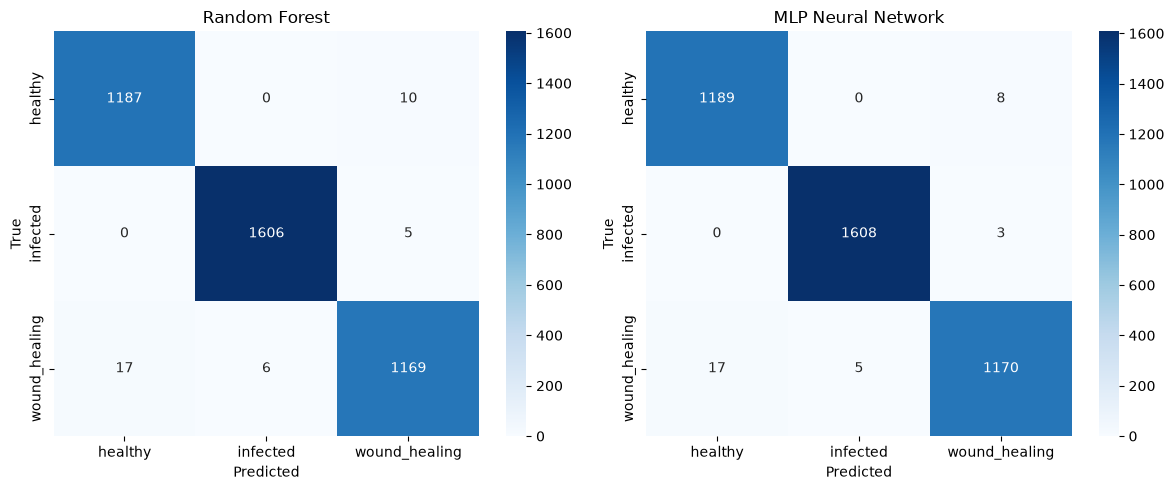

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
cm_rf = confusion_matrix(yc_test, yc_pred_rf)
cm_mlp = confusion_matrix(yc_test, yc_pred_mlp)

sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Random Forest')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')

sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('MLP Neural Network')
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('True')
plt.tight_layout()
plt.show() 

## 9. Feature Importance (Random Forest)

Shows which sensor inputs drive the classification decision.

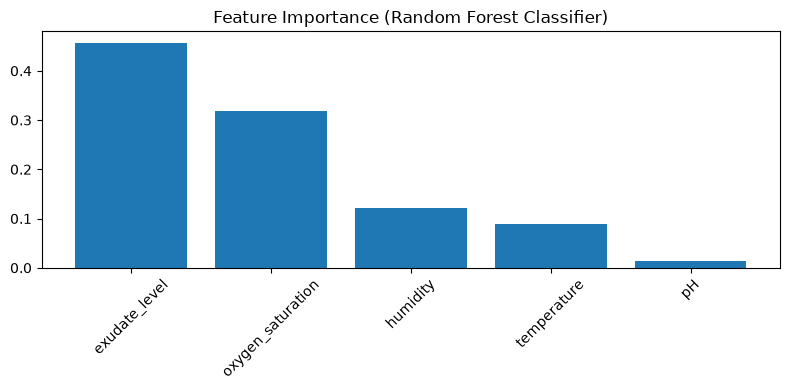

In [16]:
importances = rf_clf.feature_importances_
indices = np.argsort(importances)[::-1]
plt.figure(figsize=(8,4))
plt.title('Feature Importance (Random Forest Classifier)')
plt.bar(range(len(features)), importances[indices], align='center')
plt.xticks(range(len(features)), [features[i] for i in indices], rotation=45)
plt.tight_layout()
plt.show()

## 10. Regressor predictions vs true days

Scatter plot to see how well the models estimate healing days.

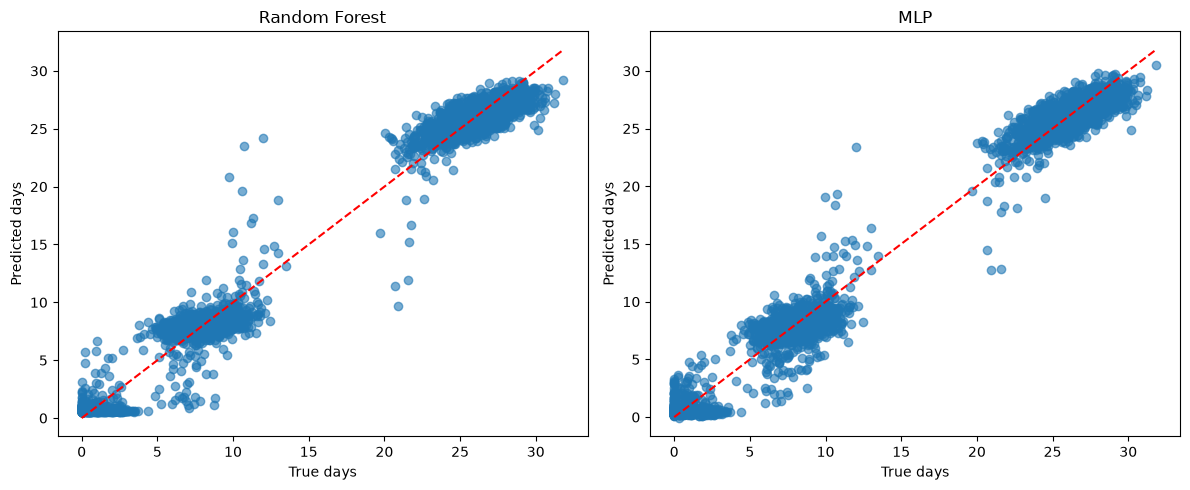

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(yd_test, yd_pred_rf, alpha=0.6)
ax[0].plot([yd_test.min(), yd_test.max()], [yd_test.min(), yd_test.max()], 'r--')
ax[0].set_xlabel('True days'); ax[0].set_ylabel('Predicted days'); ax[0].set_title('Random Forest')
ax[1].scatter(yd_test, yd_pred_mlp, alpha=0.6)
ax[1].plot([yd_test.min(), yd_test.max()], [yd_test.min(), yd_test.max()], 'r--')
ax[1].set_xlabel('True days'); ax[1].set_ylabel('Predicted days'); ax[1].set_title('MLP')
plt.tight_layout()
plt.show()

## 11. Conclusion

- **Random Forest** tends to be robust and interpretable, especially with small tabular data.
- **MLP** can capture non‑linear patterns but may require more data to generalise well.
- Based on these results, the **Random Forest** models already perform decently and are used in the live Flask app.
- The regressor’s performance is limited because the target (`healing_days`) is synthetically derived from a simple heuristic – this is clearly a placeholder until real longitudinal data becomes available.

## 12. Extended model benchmark and presentation figures

The cells below compare several classical models using the same train/test split. They also create a reusable `model_outputs/` folder containing high-resolution PNG figures for a presentation. Because `healing_days` is synthetic, treat regression results as a demonstration of the workflow rather than clinical evidence.

In [8]:
from pathlib import Path
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.svm import SVC, SVR
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor, ExtraTreesClassifier, ExtraTreesRegressor
from sklearn.metrics import f1_score, precision_score, recall_score, mean_squared_error
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier

output_dir = Path('model_outputs')
output_dir.mkdir(exist_ok=True)

classifier_models = {
    'Random Forest': (rf_clf, X_train, X_test),
    'Extra Trees': (ExtraTreesClassifier(n_estimators=300, random_state=42), X_train, X_test),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=42), X_train, X_test),
    'Logistic Regression': (LogisticRegression(max_iter=2000, random_state=42), X_train_scaled, X_test_scaled),
    'KNN': (KNeighborsClassifier(n_neighbors=5), X_train_scaled, X_test_scaled),
    'SVM': (SVC(probability=True, random_state=42), X_train_scaled, X_test_scaled),
    'MLP': (mlp_clf, X_train_scaled, X_test_scaled),
}

classifier_results = []
classifier_predictions = {}
classifier_probabilities = {}
for name, (model, train_features, test_features) in classifier_models.items():
    fitted_model = clone(model)
    fitted_model.fit(train_features, yc_train)
    predictions = fitted_model.predict(test_features)
    classifier_predictions[name] = predictions
    classifier_probabilities[name] = fitted_model.predict_proba(test_features)
    classifier_results.append({
        'Model': name,
        'Accuracy': accuracy_score(yc_test, predictions),
        'Precision (weighted)': precision_score(yc_test, predictions, average='weighted', zero_division=0),
        'Recall (weighted)': recall_score(yc_test, predictions, average='weighted', zero_division=0),
        'F1 (weighted)': f1_score(yc_test, predictions, average='weighted', zero_division=0),
    })

classifier_results_df = pd.DataFrame(classifier_results).sort_values('F1 (weighted)', ascending=False)
classifier_results_df.to_csv(output_dir / 'classifier_results.csv', index=False)
classifier_results_df

,Model,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted)
5,SVM,0.99200,0.992011,0.99200,0.991993
6,MLP,0.99175,0.991758,0.99175,0.991743
3,Logistic Regression,0.99100,0.991016,0.99100,0.990994
1,Extra Trees,0.99075,0.990747,0.99075,0.990746
0,Random Forest,0.99050,0.990500,0.99050,0.990494
2,Gradient Boosting,0.99000,0.990000,0.99000,0.989992
4,KNN,0.98725,0.987267,0.98725,0.987229


In [10]:
regressor_models = {
    'Random Forest': (RandomForestRegressor(n_estimators=300, max_depth=8, random_state=42), X_train, X_test),
    'Extra Trees': (ExtraTreesRegressor(n_estimators=300, random_state=42), X_train, X_test),
    'Gradient Boosting': (GradientBoostingRegressor(random_state=42), X_train, X_test),
    'Linear Regression': (LinearRegression(), X_train_scaled, X_test_scaled),
    'Ridge': (Ridge(alpha=1.0), X_train_scaled, X_test_scaled),
    'KNN': (KNeighborsRegressor(n_neighbors=5), X_train_scaled, X_test_scaled),
    'SVR': (SVR(kernel='rbf'), X_train_scaled, X_test_scaled),
    'MLP': (MLPRegressor(hidden_layer_sizes=(64, 32), activation='relu', solver='adam', max_iter=500, random_state=42, early_stopping=True, validation_fraction=0.1), X_train_scaled, X_test_scaled),
}

regressor_results = []
regressor_predictions = {}
for name, (model, train_features, test_features) in regressor_models.items():
    fitted_model = clone(model)
    fitted_model.fit(train_features, yd_train)
    predictions = fitted_model.predict(test_features)
    regressor_predictions[name] = predictions
    regressor_results.append({
        'Model': name,
        'MAE (days)': mean_absolute_error(yd_test, predictions),
        'RMSE (days)': mean_squared_error(yd_test, predictions, squared=False),
        'R2': r2_score(yd_test, predictions),
    })

regressor_results_df = pd.DataFrame(regressor_results).sort_values('MAE (days)')
regressor_results_df.to_csv(output_dir / 'regressor_results.csv', index=False)
regressor_results_df

,Model,MAE (days),RMSE (days),R2
7,MLP,0.949290,1.290719,0.986551
0,Random Forest,0.971286,1.340284,0.985498
1,Extra Trees,0.980754,1.330638,0.985706
2,Gradient Boosting,0.991851,1.363846,0.984984
5,KNN,1.034862,1.409957,0.983951
6,SVR,1.156826,1.567020,0.980176
4,Ridge,1.792503,2.250484,0.959113
3,Linear Regression,1.792514,2.250484,0.959113


### Presentation-ready figures

Run the next cell to generate the complete figure pack. Each figure is saved at 220 DPI so it can be inserted into PowerPoint without a screenshot.

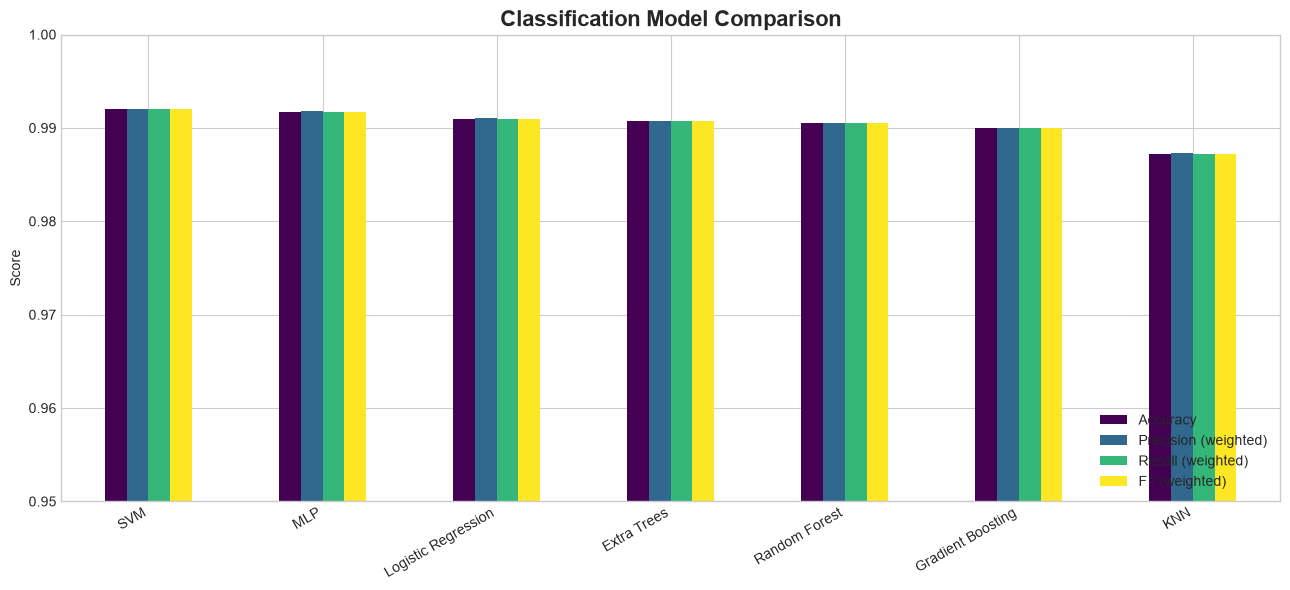

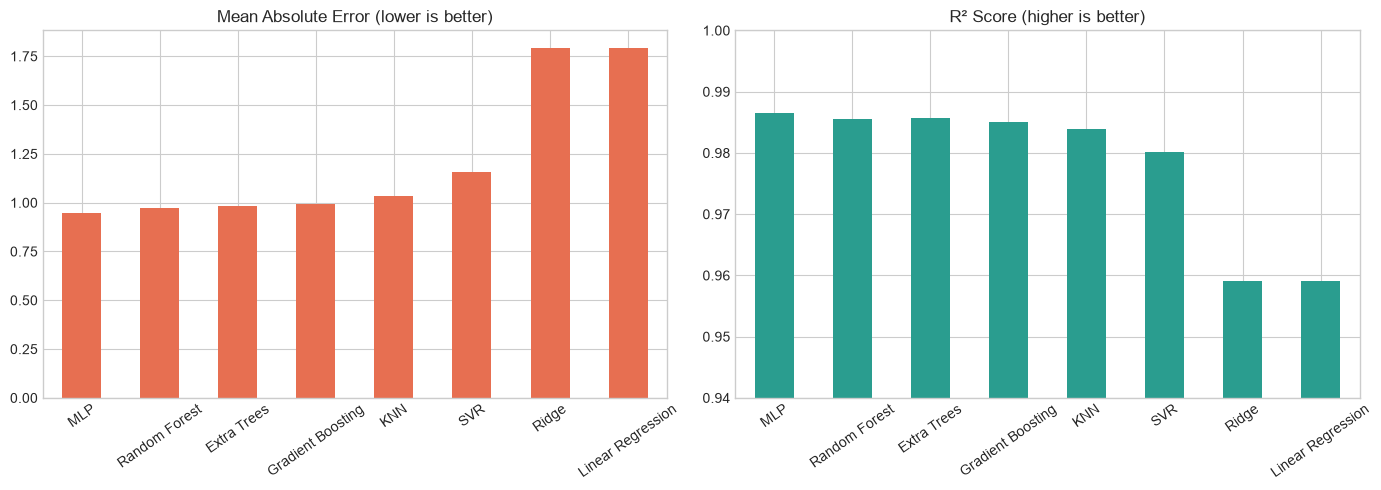

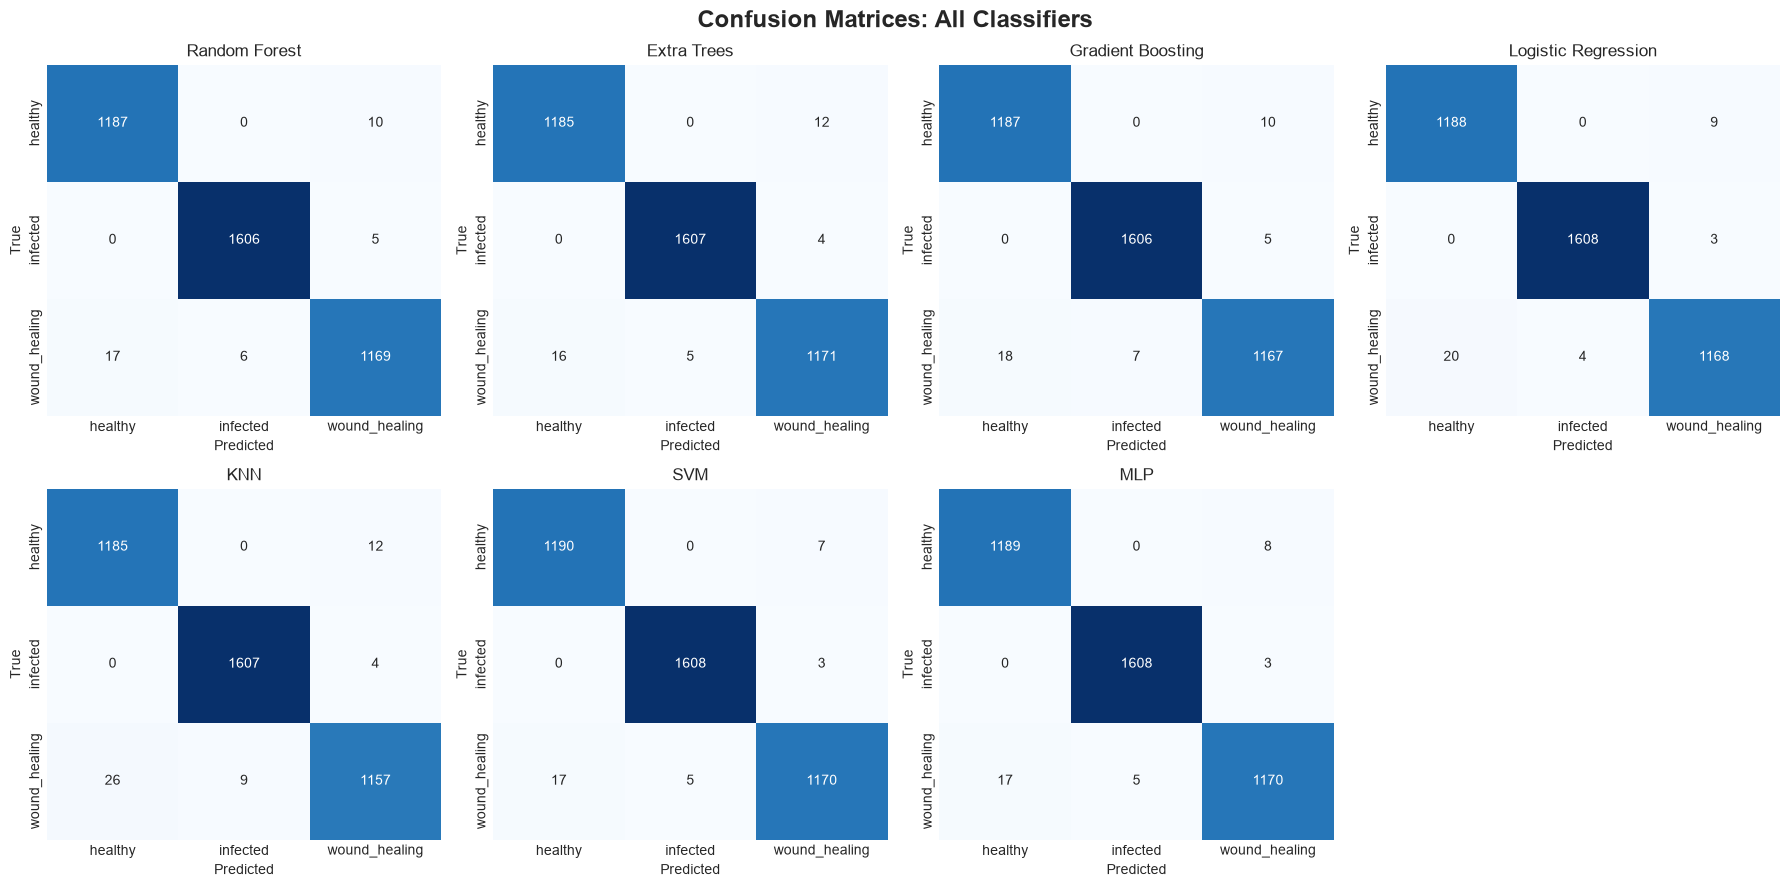

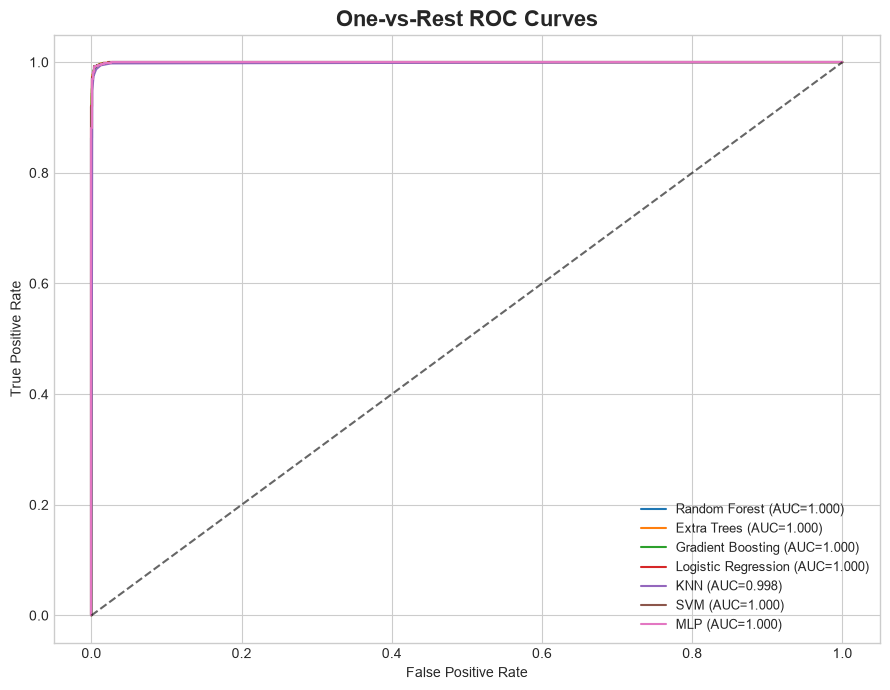

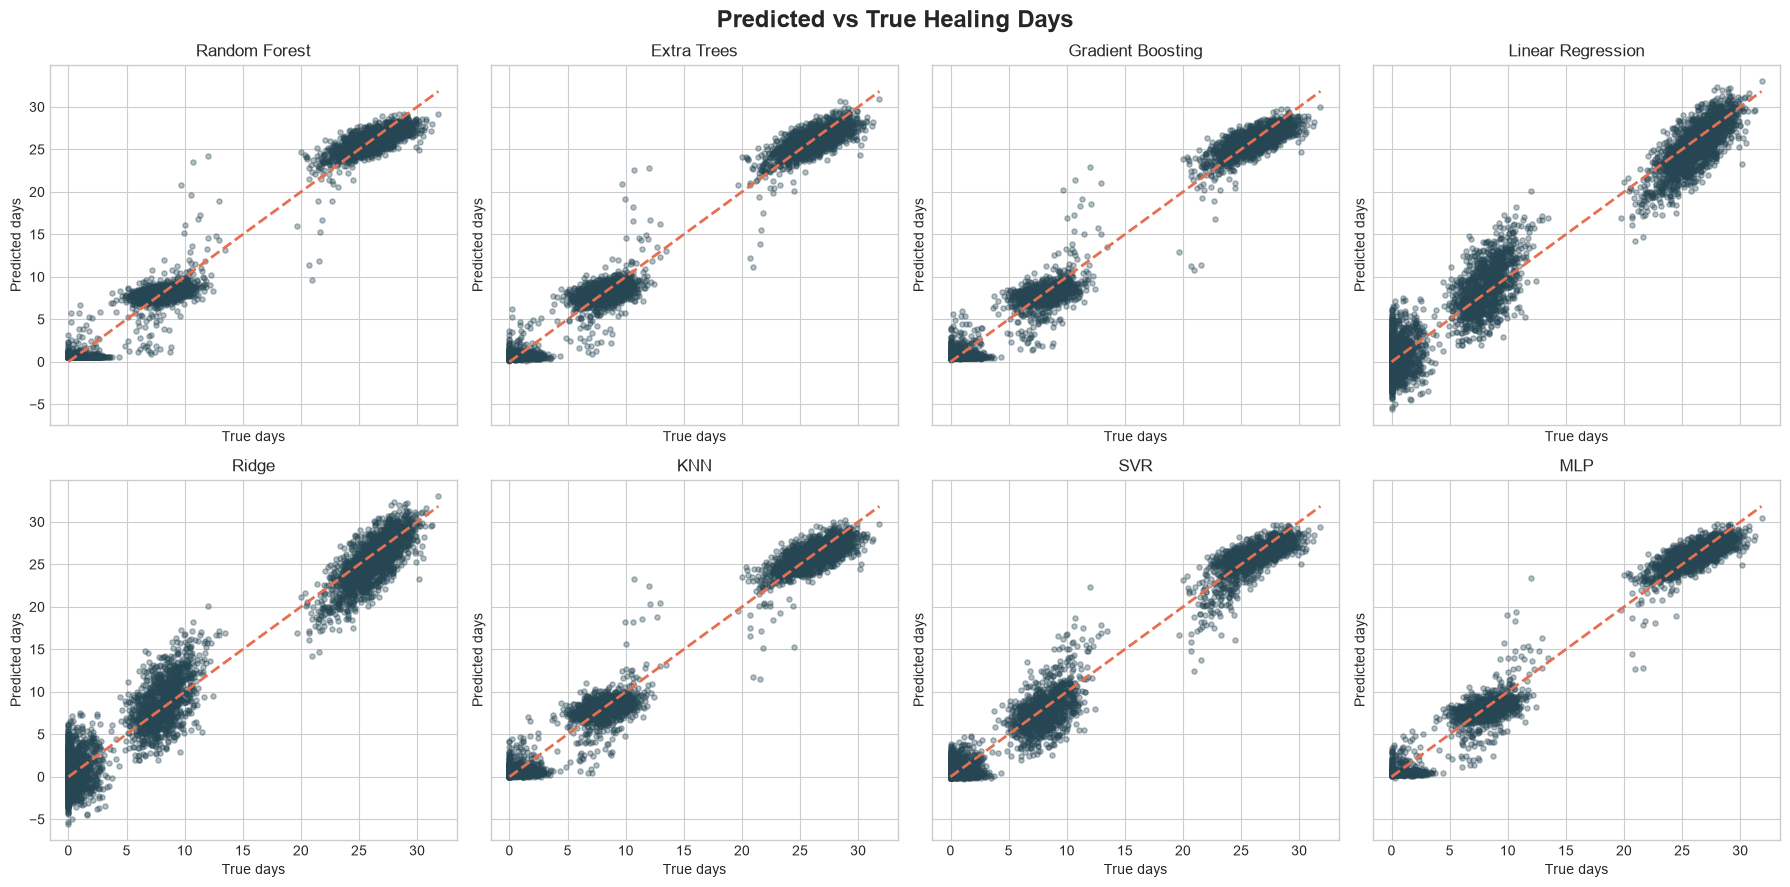

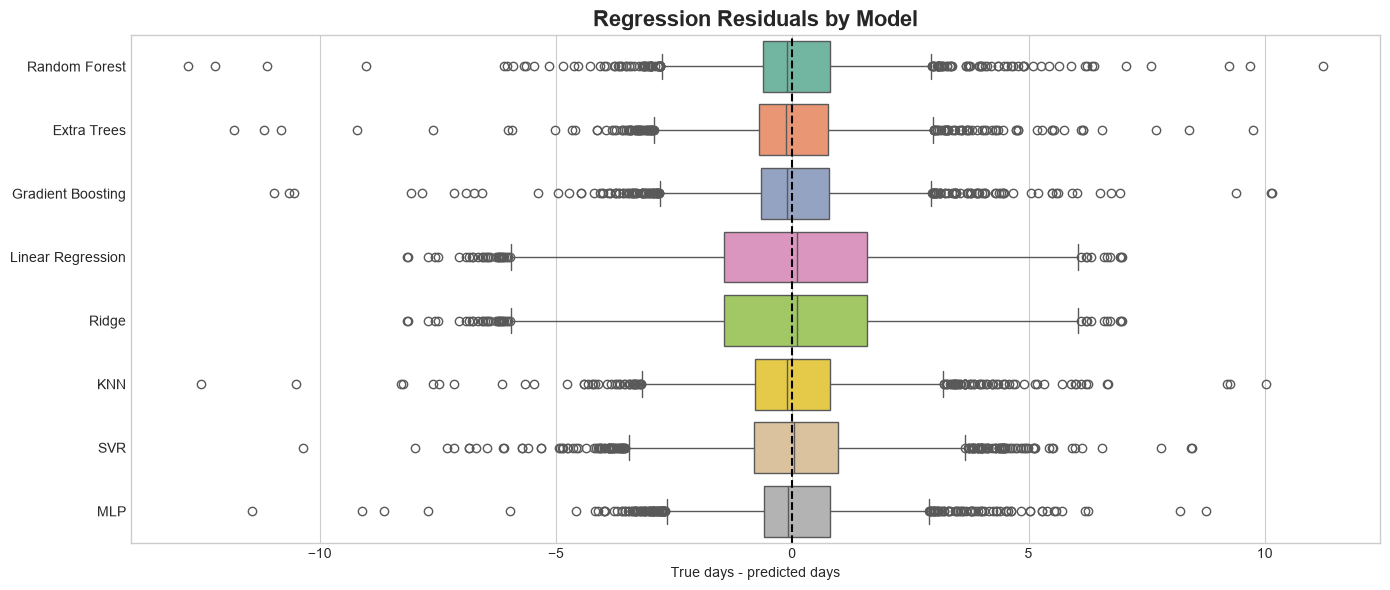

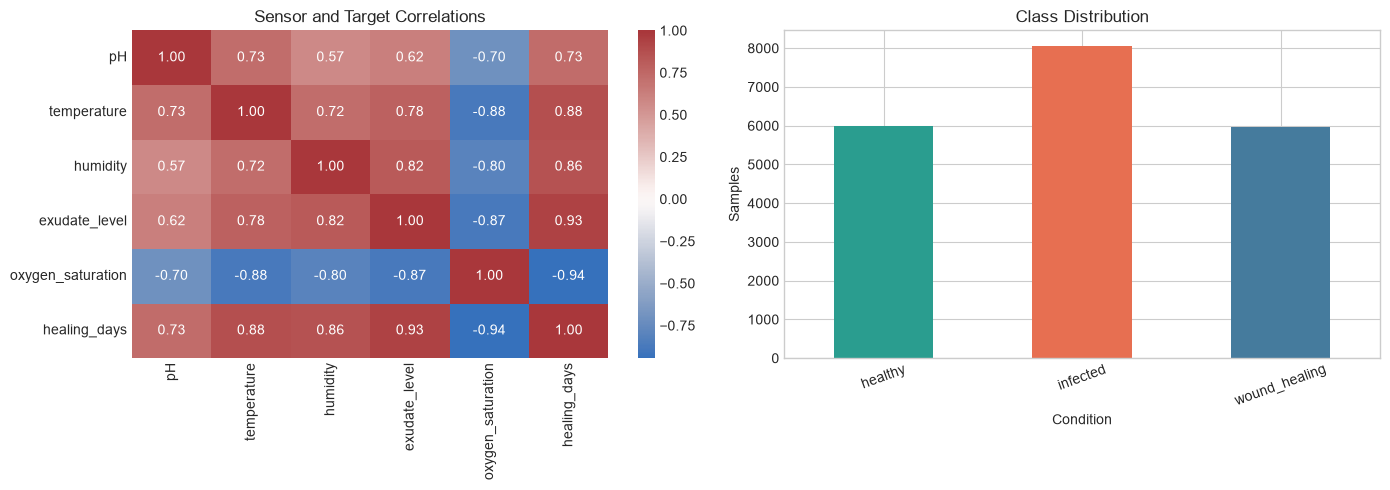

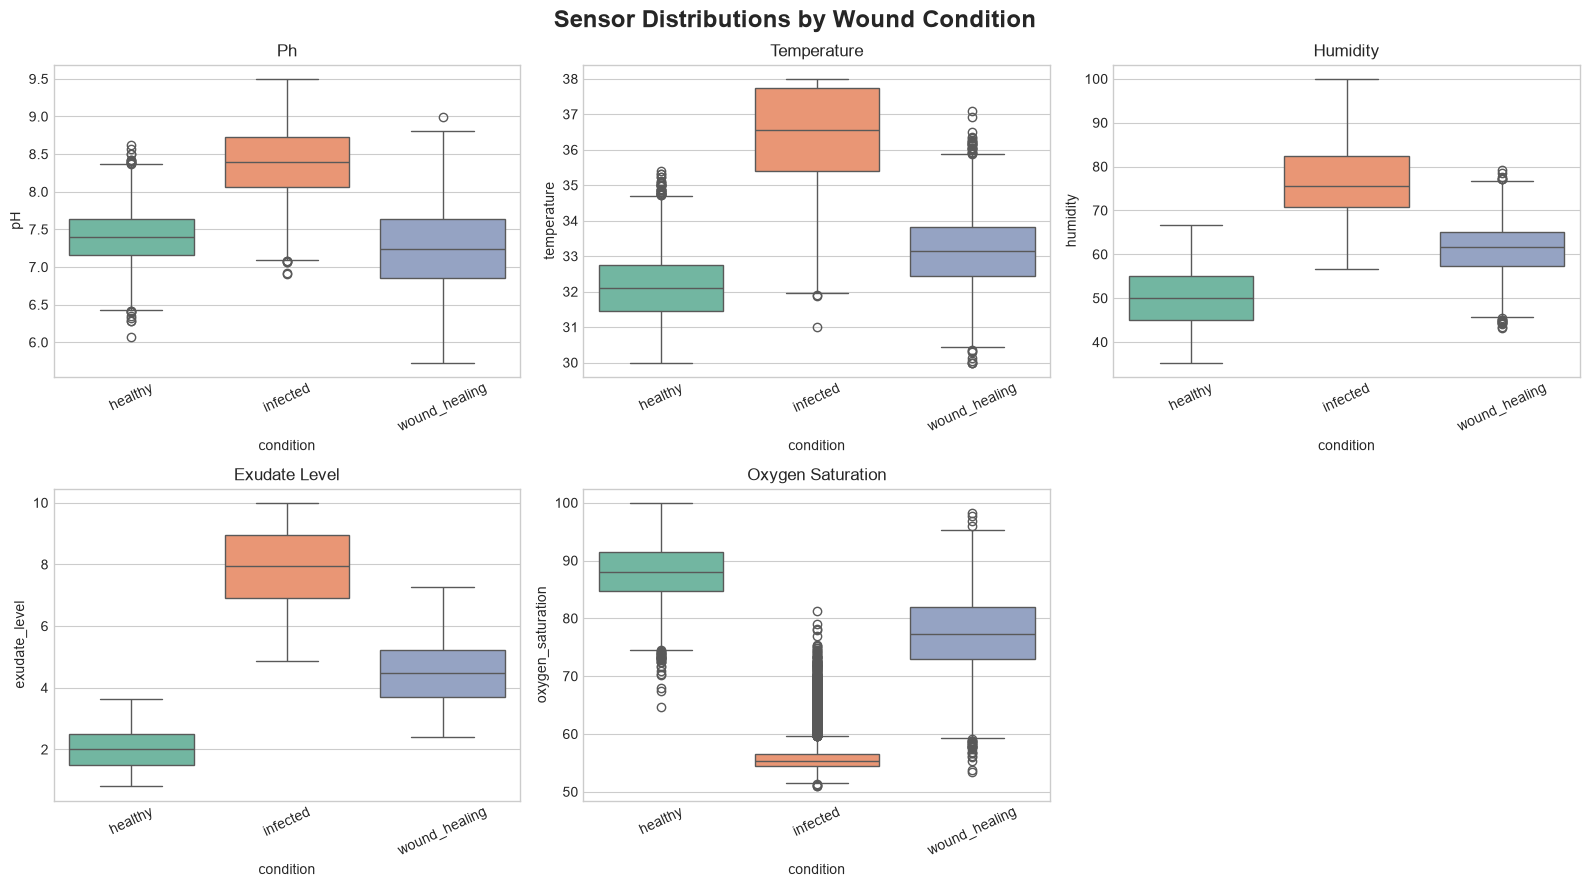

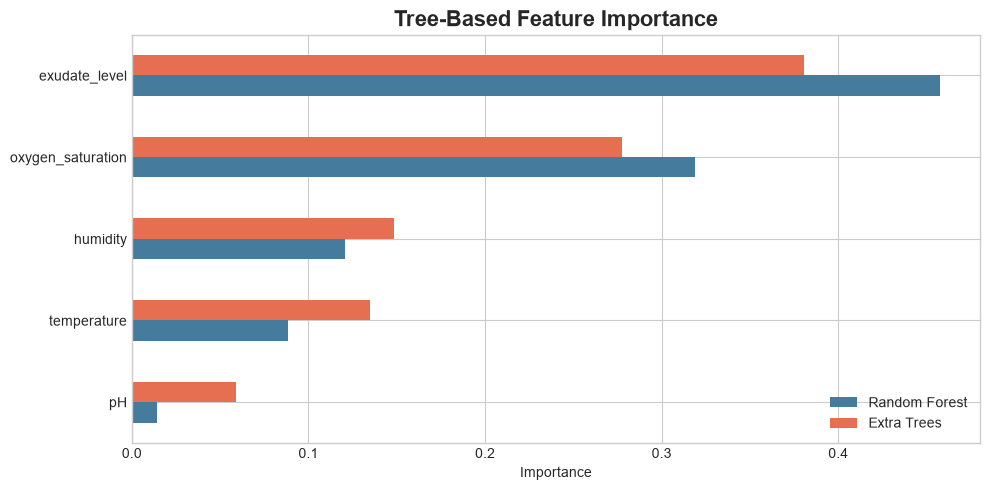

Saved 9 PNG figures and 2 CSV result tables to C:\Users\Tanu\Code\bandage\model_outputs


In [11]:
plt.style.use('seaborn-v0_8-whitegrid')

# 1. Classification metric comparison
ax = classifier_results_df.set_index('Model')[['Accuracy', 'Precision (weighted)', 'Recall (weighted)', 'F1 (weighted)']].plot(kind='bar', figsize=(13, 6), ylim=(0.95, 1.0), colormap='viridis')
ax.set_title('Classification Model Comparison', fontsize=16, weight='bold')
ax.set_ylabel('Score')
ax.set_xlabel('')
plt.xticks(rotation=30, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(output_dir / '01_classification_model_comparison.png', dpi=220, bbox_inches='tight')
plt.show()

# 2. Regression metric comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
regressor_results_df.set_index('Model')['MAE (days)'].plot(kind='bar', ax=axes[0], color='#e76f51', title='Mean Absolute Error (lower is better)')
regressor_results_df.set_index('Model')['R2'].plot(kind='bar', ax=axes[1], color='#2a9d8f', title='R² Score (higher is better)', ylim=(0.94, 1.0))
for axis in axes:
    axis.set_xlabel('')
    axis.tick_params(axis='x', rotation=35)
plt.tight_layout()
plt.savefig(output_dir / '02_regression_model_comparison.png', dpi=220, bbox_inches='tight')
plt.show()

# 3. Confusion matrices for every classifier
n_models = len(classifier_predictions)
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for axis, (name, predictions) in zip(axes.flat, classifier_predictions.items()):
    sns.heatmap(confusion_matrix(yc_test, predictions), annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=class_names, yticklabels=class_names, ax=axis)
    axis.set_title(name)
    axis.set_xlabel('Predicted')
    axis.set_ylabel('True')
axes.flat[-1].axis('off')
fig.suptitle('Confusion Matrices: All Classifiers', fontsize=17, weight='bold')
plt.tight_layout()
plt.savefig(output_dir / '03_all_confusion_matrices.png', dpi=220, bbox_inches='tight')
plt.show()

# 4. One-vs-rest ROC curves and AUC summary
true_binary = label_binarize(yc_test, classes=np.arange(len(class_names)))
fig, axis = plt.subplots(figsize=(9, 7))
for name, probabilities in classifier_probabilities.items():
    from sklearn.metrics import roc_auc_score
    auc_value = roc_auc_score(true_binary, probabilities, multi_class='ovr', average='weighted')
    axis.plot(*__import__('sklearn').metrics.roc_curve(true_binary.ravel(), probabilities.ravel())[:2], label=f'{name} (AUC={auc_value:.3f})')
axis.plot([0, 1], [0, 1], 'k--', alpha=0.6)
axis.set_title('One-vs-Rest ROC Curves', fontsize=16, weight='bold')
axis.set_xlabel('False Positive Rate')
axis.set_ylabel('True Positive Rate')
axis.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig(output_dir / '04_multiclass_roc_curves.png', dpi=220, bbox_inches='tight')
plt.show()

# 5. Predicted-vs-true scatter plots for every regressor
fig, axes = plt.subplots(2, 4, figsize=(18, 9), sharex=True, sharey=True)
line_limits = [yd_test.min(), yd_test.max()]
for axis, (name, predictions) in zip(axes.flat, regressor_predictions.items()):
    axis.scatter(yd_test, predictions, alpha=0.35, s=14, color='#264653')
    axis.plot(line_limits, line_limits, '--', color='#e76f51', linewidth=2)
    axis.set_title(name)
    axis.set_xlabel('True days')
    axis.set_ylabel('Predicted days')
for axis in axes.flat[len(regressor_predictions):]:
    axis.axis('off')
fig.suptitle('Predicted vs True Healing Days', fontsize=17, weight='bold')
plt.tight_layout()
plt.savefig(output_dir / '05_all_regression_scatterplots.png', dpi=220, bbox_inches='tight')
plt.show()

# 6. Residual distributions
residuals = pd.DataFrame({name: yd_test - predictions for name, predictions in regressor_predictions.items()})
plt.figure(figsize=(14, 6))
sns.boxplot(data=residuals, orient='h', palette='Set2')
plt.axvline(0, color='black', linestyle='--')
plt.title('Regression Residuals by Model', fontsize=16, weight='bold')
plt.xlabel('True days - predicted days')
plt.tight_layout()
plt.savefig(output_dir / '06_regression_residuals.png', dpi=220, bbox_inches='tight')
plt.show()

# 7. Sensor correlation and class balance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(df[features + ['healing_days']].corr(), annot=True, fmt='.2f', cmap='vlag', center=0, ax=axes[0])
axes[0].set_title('Sensor and Target Correlations')
df['condition'].value_counts().reindex(class_names).plot(kind='bar', ax=axes[1], color=['#2a9d8f', '#e76f51', '#457b9d'])
axes[1].set_title('Class Distribution')
axes[1].set_xlabel('Condition')
axes[1].set_ylabel('Samples')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.savefig(output_dir / '07_correlation_and_class_balance.png', dpi=220, bbox_inches='tight')
plt.show()

# 8. Sensor distributions by wound condition
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for axis, feature in zip(axes.flat, features):
    sns.boxplot(data=df, x='condition', y=feature, order=class_names, ax=axis, palette='Set2')
    axis.set_title(feature.replace('_', ' ').title())
    axis.tick_params(axis='x', rotation=25)
axes.flat[-1].axis('off')
fig.suptitle('Sensor Distributions by Wound Condition', fontsize=17, weight='bold')
plt.tight_layout()
plt.savefig(output_dir / '08_sensor_distributions_by_condition.png', dpi=220, bbox_inches='tight')
plt.show()

# 9. Feature importance comparison for tree classifiers
importance_models = {
    'Random Forest': classifier_models['Random Forest'][0],
    'Extra Trees': classifier_models['Extra Trees'][0],
}
importance_table = pd.DataFrame({name: clone(model).fit(X_train, yc_train).feature_importances_ for name, model in importance_models.items()}, index=features)
importance_table.sort_values('Random Forest').plot(kind='barh', figsize=(10, 5), color=['#457b9d', '#e76f51'])
plt.title('Tree-Based Feature Importance', fontsize=16, weight='bold')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig(output_dir / '09_tree_feature_importance.png', dpi=220, bbox_inches='tight')
plt.show()

print(f'Saved {len(list(output_dir.glob("*.png")))} PNG figures and 2 CSV result tables to {output_dir.resolve()}')